# Dummy single photoelectron (SPE) area distributions

When a photoelectron (PE) is amplified by a PMT, the resulting charge fluctuates from PE to PE. The distribution of this charge, measured in units of the mean SPE charge, is the **SPE area distribution** (or SPE spectrum). It is measured for every PMT, e.g. with an LED calibration.

The ember plugin `S1PhotonPropagation` (like fuse) uses it to give each detected photon a gain: `photon_gain = PMT gain × SPE factor`, where the SPE factor is drawn from the spectrum of the photon's channel. The waveform simulation later scales the SPE pulse shape with this gain.

This notebook writes a **dummy spectrum**: the same Gaussian for every channel, with a mean of 1 PE and a width of $\sigma = 0.35$ PE, cut at 0. Real spectra also contain an exponential part of under-amplified PEs at small charges; replace the dummy table with measured spectra if you have them.

### Format

A CSV table with one row per charge bin:

| Column | Content |
|---|---|
| `charge` | Charge of the bin in units of the mean SPE charge (PE). |
| `0`, `1`, …, `n-1` | Probability (or number of entries) of the bin for each channel. The columns are found by name, so their order does not matter. |

The spectra do not need to be normalized. The plugin builds the cumulative distribution of every channel and draws from it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import strax

import ember
from ember.url_protocols import DUMMY_MAP_DIRECTORY

In [2]:
n_tpc_pmts = strax.URLConfig.evaluate_dry("detector://n_tpc_pmts")

spe_mean = 1.0  # PE
spe_width = 0.35  # PE
charge = np.round(np.arange(-1.0, 5.0, 0.01), 2)  # PE, same binning as fuse's tables

gaussian = np.exp(-0.5 * ((charge - spe_mean) / spe_width) ** 2)
gaussian[charge <= 0] = 0.0
gaussian /= gaussian.sum()

spe_columns = {"charge": charge}
for channel in range(n_tpc_pmts):
    spe_columns[str(channel)] = gaussian
spe_table = pd.DataFrame(spe_columns)

spe_table.iloc[95:105, :4]

,charge,0,1,2
95,-0.05,0.000000,0.000000,0.000000
96,-0.04,0.000000,0.000000,0.000000
97,-0.03,0.000000,0.000000,0.000000
98,-0.02,0.000000,0.000000,0.000000
99,-0.01,0.000000,0.000000,0.000000
100,0.00,0.000000,0.000000,0.000000
101,0.01,0.000209,0.000209,0.000209
102,0.02,0.000227,0.000227,0.000227
103,0.03,0.000245,0.000245,0.000245
104,0.04,0.000266,0.000266,0.000266


The mean of the cut Gaussian is slightly above 1 PE, because the negative tail is removed:

Mean SPE charge: 1.0024597820302115 PE


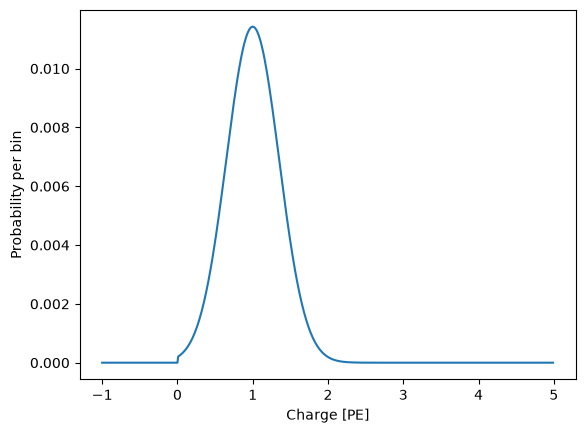

In [3]:
print("Mean SPE charge:", np.sum(charge * gaussian), "PE")

plt.plot(charge, gaussian)
plt.xlabel("Charge [PE]")
plt.ylabel("Probability per bin")
plt.show()

In [4]:
output_file = DUMMY_MAP_DIRECTORY / "spe_distributions_dummy.csv"
spe_table.to_csv(output_file, index=False, float_format="%.6g")
print("Saved", output_file)

Saved /mnt/d/XLZD/mymodules/ember/ember/dummy_maps/spe_distributions_dummy.csv
